## Supervised Learning
## Goal: Predict avg_daily_sales using our training data

Focus on:
1. Dataset Overview 
2. identify missing columns  
3. Data Distribution...log transform...
(Features: population and density, median income, competitors nearby, walkability, traffic, jobs nearby, and business type.)
3.1 Target Variable Distribution
4. Features relationship with sales, correlations...
5. Model: Linear Regression, Decision Tree, Random Forest 
6. Compare validation Mean Absolute Error (MAE), Root Mean Squared (RMSE), R^2 
7. Test with test data set 


## Import Libraries

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

import matplotlib.pyplot as plt

# Data Overview
read in train / val / test parquet file

In [87]:
#Read-in train dataset
df = pd.read_parquet('../data/modeling/train_data.parquet')

df.info
print(df.describe().round(2))

       avg_daily_sales  longitude  latitude  competitors_within_1_mi  \
count          8669.00    8669.00   8669.00                  8669.00   
mean           2349.19     -74.68     41.63                    44.38   
std            2886.29       1.65      1.11                    54.92   
min               0.41     -79.76     40.51                     0.00   
25%             669.08     -75.22     40.72                     6.00   
50%            1483.95     -73.93     40.89                    18.00   
75%            2929.67     -73.78     42.78                    67.00   
max           62358.43     -71.94     45.00                   249.00   

       aadt_count  aadt_lanes  dist_to_read_m  median_household_income  \
count     8647.00     8617.00         8667.00                  7788.00   
mean     11984.68        3.62           24.99                 93986.05   
std      11037.71        2.91           53.99                 48121.03   
min          2.00        1.00            0.00          

#### Number of Retailers and Features

In [65]:
# Number of features in the data
features = [data for data in df.select_dtypes("number").columns if data not in ["avg_daily_sales", "longitude", "latitude"]]

print('\n'f"{len(df)} retailers" ' & ' f"{len(features)} numeric features")


8669 retailers & 48 numeric features


In [17]:
#Convert all columns except "chain" and "bustype" to numeric to review missing values and impute missing values
string_cols = ["chain", "bustype"]  # replace with your column names

# Keep these columns as pandas strings
df[string_cols] = df[string_cols].astype("string")

# Convert all remaining columns to numeric
numeric_cols = df.columns.difference(string_cols)
df[numeric_cols] = df[numeric_cols].apply(
    pd.to_numeric,
    errors="coerce"
)

## Missing Values

In [ ]:
#percentage of missing data 
missing_data = (df[features].isna().mean() * 100).sort_values(ascending=False).round(2).astype(str) + '%'

print(missing_data)

D1C                                   18.34%
D1B                                   18.34%
NatWalkInd                            18.34%
D3A                                   18.34%
median_household_income               10.16%
poverty_rate                           1.26%
family_households_proportion           1.26%
owner_occupied_proportion              1.26%
no_vehicle_households_proportion       1.26%
unemployment_rate                      1.23%
age_30_64_proportion                   1.13%
post_grad_degree_proportion_25plus     1.13%
labor_force_participation_rate         1.13%
age_18_29_proportion                   1.13%
bachelors_degree_proportion_25plus     1.13%
aadt_lanes                              0.6%
total_population                       0.53%
commercial_places_within_1_mi          0.36%
community_places_within_1_mi           0.36%
aadt_count                             0.25%
wac_cns07                              0.08%
wac_cns17                              0.08%
wac_cns16 

In [ ]:
#Review missing values
summary = df.describe()

summary.loc['missing_values'] = df.isna().sum()
summary

#Export to CSV for full review
#summary.to_csv('/Users/brisabol/Documents/MADS/SIADS 696/train_missing.csv', index=True)

#Consider removing outlier(s) from average daily sales???

,avg_daily_sales,longitude,latitude,competitors_within_1_mi,aadt_count,aadt_lanes,dist_to_read_m,median_household_income,total_population,age_18_29_proportion,...,wac_cns14,wac_cns15,wac_cns16,wac_cns17,wac_cns18,wac_cns19,wac_cns20,wac_c000,wac_ce01_prop,wac_ce02_prop
count,8669.000000,8669.000000,8669.000000,8669.000000,8647.000000,8617.000000,8667.000000,7788.000000,8623.000000,8571.000000,...,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000,8662.000000
mean,2349.192381,-74.681130,41.630837,44.379513,11984.681277,3.619937,24.988821,93986.047766,1068.401484,0.192171,...,80.036712,87.963057,190.077927,18.079081,104.319788,46.922766,133.643039,1292.232163,0.215783,0.321424
std,2886.293329,1.648507,1.113746,54.924159,11037.711299,2.913371,53.990787,48121.032220,498.095052,0.112650,...,429.751661,427.936950,989.100283,89.970491,238.059210,141.996281,1340.817884,4090.103197,0.099802,0.117556
min,0.413333,-79.759770,40.511420,0.000000,2.000000,1.000000,0.000185,2499.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,669.078082,-75.222490,40.724830,6.000000,5436.000000,2.000000,0.882020,60106.000000,724.000000,0.117026,...,0.000000,0.000000,6.000000,0.000000,8.000000,5.000000,0.000000,152.000000,0.142857,0.245283
50%,1483.953425,-73.932190,40.890840,18.000000,9569.000000,2.000000,3.167199,83359.000000,994.000000,0.177368,...,5.000000,1.000000,28.000000,0.000000,34.000000,15.000000,0.000000,382.000000,0.208986,0.311834
75%,2929.672603,-73.777160,42.782530,67.000000,15712.000000,4.000000,28.991627,118828.000000,1338.000000,0.244255,...,23.750000,60.750000,105.000000,5.000000,103.000000,37.000000,0.000000,952.000000,0.276281,0.387500
max,62358.432877,-71.943160,44.997930,249.000000,199411.000000,33.000000,1531.709991,250001.000000,7527.000000,1.000000,...,7969.000000,31117.000000,41063.000000,1746.000000,3528.000000,2008.000000,33461.000000,58601.000000,1.000000,1.000000
missing_values,0.000000,0.000000,0.000000,0.000000,22.000000,52.000000,2.000000,881.000000,46.000000,98.000000,...,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000


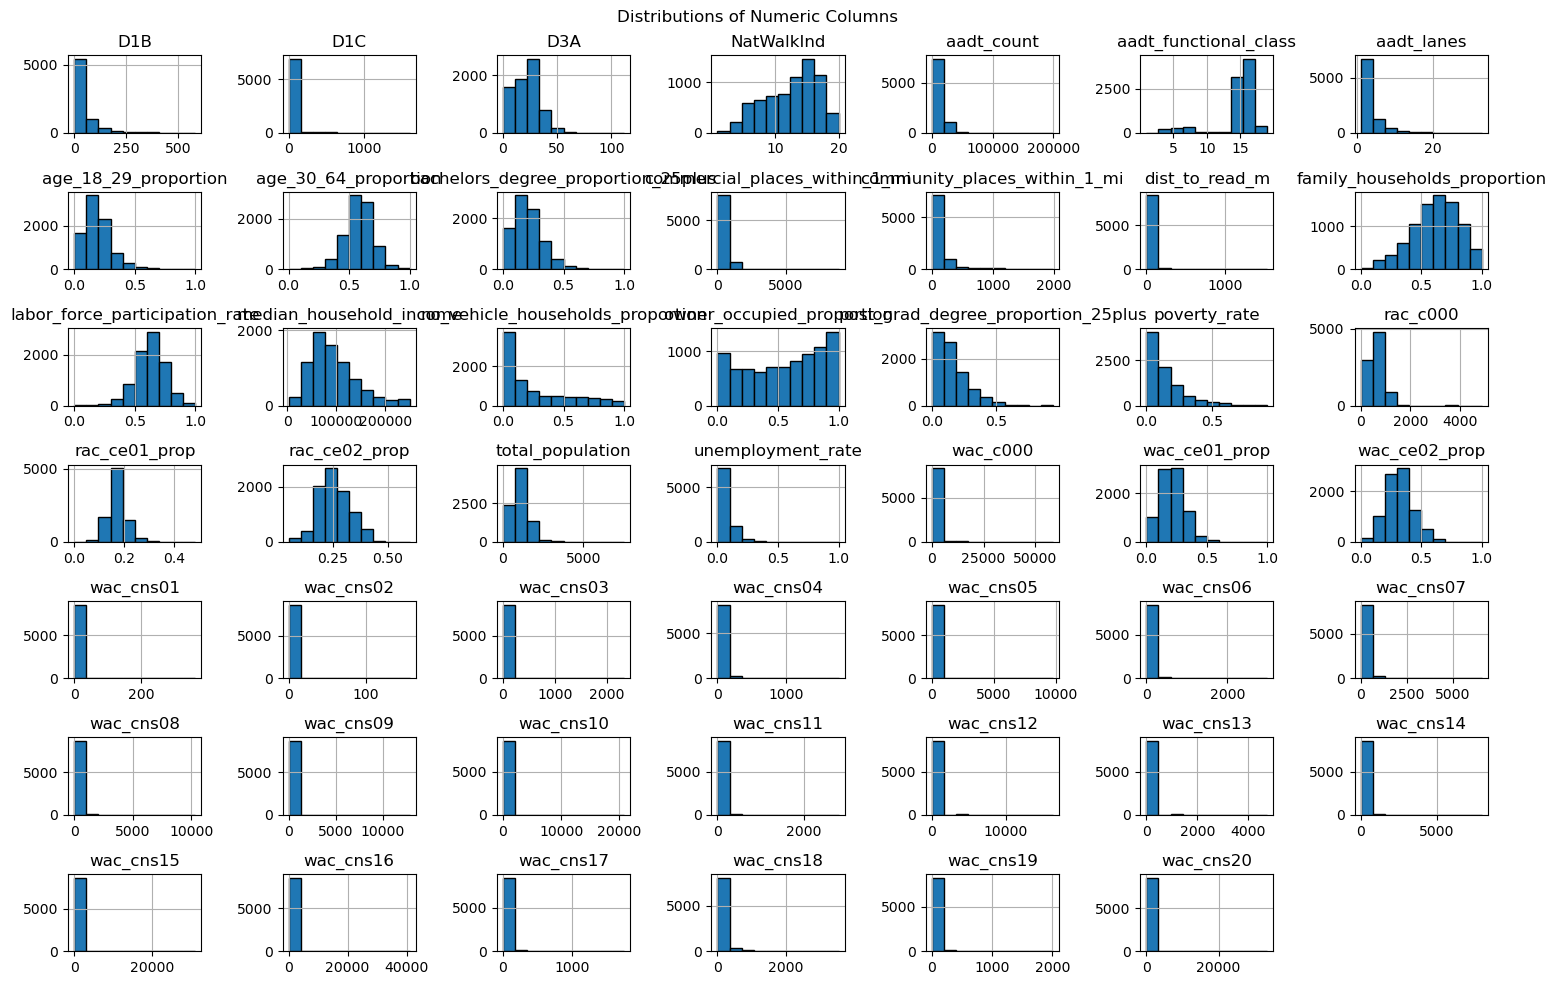

In [11]:
#Review histogram of columns to determin which method for imputation
#Ignore columns with no missing values and string type, including agtno to competitors_within_1_mi
ignore_columns = ["agtno", "avg_daily_sales", "chain", "bustype", "longitude", "latitude",
                  "bg_geoid", "tract_geoid", "competitors_within_1_mi"]
numeric_columns2 = df.columns.difference(ignore_columns)

df[numeric_columns2].hist(
    bins=10,
    figsize=(15, 10),
    edgecolor="black"
)

plt.suptitle("Distributions of Numeric Columns")
plt.tight_layout()
plt.show()

In [27]:
#Perform imputation of missing values on all columns except ignore_columns

preprocessor = ColumnTransformer(
    transformers=[
        ("mean_imputer",
         SimpleImputer(strategy="mean"),
         ["median_household_income", "age_18_29_proportion", "age_30_64_proportion", 
           "bachelors_degree_proportion_25plus", "labor_force_participation_rate", "family_households_proportion",
           "owner_occupied_proportion", "D3A", "NatWalkInd", "rac_ce01_prop", "rac_ce02_prop", "wac_ce01_prop", "wac_ce02_prop"]),

        ("median_imputer",
         SimpleImputer(strategy="median"),
         ["aadt_count", "aadt_functional_class", "aadt_lanes", "dist_to_read_m", "total_population",
           "poverty_rate", "post_grad_degree_proportion_25plus", "unemployment_rate",
           "no_vehicle_households_proportion", "D1B", "D1C", "commercial_places_within_1_mi", "community_places_within_1_mi",
           "rac_c000", "wac_cns01", "wac_cns02", "wac_cns03", "wac_cns04", "wac_cns05", "wac_cns06", "wac_cns07", "wac_cns08",
           "wac_cns09", "wac_cns10", "wac_cns11", "wac_cns12", "wac_cns13", "wac_cns14", "wac_cns15", "wac_cns16", "wac_cns17",
           "wac_cns18", "wac_cns19", "wac_cns20", "wac_c000"])
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)

preprocessor.set_output(transform="pandas")


df_imputed = preprocessor.fit_transform(df)

df_imputed

,median_household_income,age_18_29_proportion,age_30_64_proportion,bachelors_degree_proportion_25plus,labor_force_participation_rate,family_households_proportion,owner_occupied_proportion,D3A,NatWalkInd,rac_ce01_prop,...,wac_c000,agtno,avg_daily_sales,chain,bustype,longitude,latitude,bg_geoid,tract_geoid,competitors_within_1_mi
0,137588.000000,0.201807,0.728916,0.271875,0.716867,0.467213,0.000000,27.016522,10.500000,0.094340,...,32078.0,100006,2989.605479,independent,NYC NEWSSTAND,-73.98193,40.75969,360610125001,36061012500,224.0
1,96111.000000,0.312210,0.640649,0.137688,0.787481,0.703922,0.474510,21.765083,12.541908,0.147395,...,322.0,100013,4147.939394,independent,GAS,-73.42486,40.69660,361031233044,36103123304,23.0
2,93986.047766,0.017117,0.813693,0.710994,0.664921,0.575630,0.756303,21.765083,12.541908,0.076190,...,485.0,100028,4000.453425,independent,CONV. STORE,-73.95721,40.76617,360610126014,36061012601,95.0
3,93986.047766,0.076818,0.540466,0.061693,0.527517,0.321343,0.750600,3.723396,4.666667,0.167920,...,46.0,100047,1833.794521,independent,CONV. STORE,-74.02479,42.17531,360390811011,36039081101,0.0
4,81820.000000,0.073548,0.587097,0.190798,0.427923,0.810888,0.716332,3.380415,4.666667,0.187994,...,3499.0,100048,3552.153425,independent,CONV. STORE,-74.12407,41.32219,360710139003,36071013900,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8664,85078.000000,0.438384,0.537374,0.352014,0.663768,0.275689,0.225564,27.472849,17.833333,0.174790,...,743.0,99717,2825.932877,independent,CONV. STORE,-73.99624,40.72106,360610041006,36061004100,203.0
8665,84286.000000,0.271547,0.609209,0.468305,0.926800,0.422311,0.123506,26.636415,15.666667,0.133178,...,812.0,99757,9046.871233,independent,DELI-GROCERY,-74.02671,40.62093,360470160004,36047016000,81.0
8666,66786.000000,0.256367,0.657046,0.120654,0.607810,0.592000,0.276000,17.368700,11.666667,0.265985,...,85.0,99799,1332.806849,independent,DRUG STORE,-73.99264,40.61669,360470260002,36047026000,131.0
8667,62857.000000,0.164565,0.617784,0.215573,0.604167,0.669255,0.172360,28.916170,19.666667,0.251163,...,4320.0,99866,4740.328767,independent,GROCERY STORE,-73.81502,40.76230,360811167001,36081116700,108.0


In [28]:
#Check imputation

summary = df_imputed.describe()

summary.loc['missing_values'] = df_imputed.isna().sum()
summary

#Export to CSV for full review
#summary.to_csv('/Users/brisabol/Documents/MADS/SIADS 696/train_missing_check.csv', index=True)

,median_household_income,age_18_29_proportion,age_30_64_proportion,bachelors_degree_proportion_25plus,labor_force_participation_rate,family_households_proportion,owner_occupied_proportion,D3A,NatWalkInd,rac_ce01_prop,...,wac_cns16,wac_cns17,wac_cns18,wac_cns19,wac_cns20,wac_c000,avg_daily_sales,longitude,latitude,competitors_within_1_mi
count,8669.000000,8669.000000,8669.000000,8669.000000,8669.000000,8669.000000,8669.000000,8669.000000,8669.000000,8669.000000,...,8669.000000,8669.000000,8669.000000,8669.000000,8669.000000,8669.000000,8669.000000,8669.000000,8669.000000,8669.000000
mean,93986.047766,0.192171,0.579539,0.205648,0.625613,0.615393,0.547724,21.765083,12.541908,0.172211,...,189.947053,18.064483,104.263006,46.896989,133.535125,1291.497174,2349.192381,-74.681130,41.630837,44.379513
std,45610.052340,0.112011,0.115414,0.118993,0.125581,0.189607,0.311417,11.138949,3.738147,0.036759,...,988.711539,89.935621,237.971450,141.941831,1340.281750,4088.533105,2886.293329,1.648507,1.113746,54.924159
min,2499.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.092342,1.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.413333,-79.759770,40.511420,0.000000
25%,62656.000000,0.117647,0.514576,0.119597,0.553110,0.495671,0.285412,15.157034,10.166667,0.149798,...,6.000000,0.000000,8.000000,5.000000,0.000000,153.000000,669.078082,-75.222490,40.724830,6.000000
50%,90667.000000,0.179036,0.582425,0.193103,0.627876,0.628337,0.580762,21.765083,12.541908,0.168646,...,28.000000,0.000000,34.000000,15.000000,0.000000,382.000000,1483.953425,-73.932190,40.890840,18.000000
75%,113750.000000,0.243502,0.652715,0.275478,0.706550,0.755034,0.828629,28.100337,15.333333,0.190625,...,105.000000,5.000000,103.000000,37.000000,0.000000,952.000000,2929.672603,-73.777160,42.782530,67.000000
max,250001.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,111.879823,20.000000,0.486647,...,41063.000000,1746.000000,3528.000000,2008.000000,33461.000000,58601.000000,62358.432877,-71.943160,44.997930,249.000000
missing_values,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [29]:
#Log transformation 

ignore_columns2 = ["agtno", "chain", "bustype", "longitude", "latitude", "bg_geoid", "tract_geoid"]
cols = df_imputed.columns.difference(ignore_columns2)

df_imputed[cols] = np.log1p(df_imputed[cols])

df_imputed

#Note: historgram distributions look better after log transformation


,median_household_income,age_18_29_proportion,age_30_64_proportion,bachelors_degree_proportion_25plus,labor_force_participation_rate,family_households_proportion,owner_occupied_proportion,D3A,NatWalkInd,rac_ce01_prop,...,wac_c000,agtno,avg_daily_sales,chain,bustype,longitude,latitude,bg_geoid,tract_geoid,competitors_within_1_mi
0,11.832026,0.183826,0.547494,0.240492,0.540501,0.383365,0.000000,3.332794,2.442347,0.090151,...,10.375957,100006,8.003231,independent,NYC NEWSSTAND,-73.98193,40.75969,360610125001,36061012500,5.416100
1,11.473269,0.271713,0.495092,0.128999,0.580807,0.532932,0.388326,3.125228,2.605789,0.137494,...,5.777652,100013,8.330608,independent,GAS,-73.42486,40.69660,361031233044,36103123304,3.178054
2,11.450912,0.016972,0.595365,0.537075,0.509778,0.454655,0.563211,3.125228,2.605789,0.073427,...,6.186209,100028,8.294413,independent,CONV. STORE,-73.95721,40.76617,360610126014,36061012601,4.564348
3,11.450912,0.074010,0.432085,0.059865,0.423643,0.278649,0.559958,1.552528,1.734601,0.155224,...,3.850148,100047,7.514688,independent,CONV. STORE,-74.02479,42.17531,360390811011,36039081101,0.000000
4,11.312289,0.070969,0.461906,0.174624,0.356221,0.593817,0.540190,1.477143,1.734601,0.172266,...,8.160518,100048,8.175591,independent,CONV. STORE,-74.12407,41.32219,360710139003,36071013900,1.386294
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8664,11.351336,0.363520,0.430076,0.301595,0.509085,0.243487,0.203401,3.348951,2.935628,0.161089,...,6.612041,99717,7.946948,independent,CONV. STORE,-73.99624,40.72106,360610041006,36061004100,5.318120
8665,11.341983,0.240234,0.475743,0.384109,0.655861,0.352283,0.116454,3.319134,2.813411,0.125026,...,6.700731,99757,9.110285,independent,DELI-GROCERY,-74.02671,40.62093,360470160004,36047016000,4.406719
8666,11.109264,0.228224,0.505036,0.113913,0.474873,0.464991,0.243730,2.910648,2.538974,0.235850,...,4.454347,99799,7.195792,independent,DRUG STORE,-73.99264,40.61669,360470260002,36047026000,4.882802
8667,11.048633,0.152348,0.481057,0.195216,0.472604,0.512377,0.159019,3.398399,3.028522,0.224073,...,8.371242,99866,8.464073,independent,GROCERY STORE,-73.81502,40.76230,360811167001,36081116700,4.691348


## Target Variable - Sales Distribution

In [81]:
target = df["avg_daily_sales"]
sales = pd.to_numeric(target, errors='coerce').dropna()
sales_summary = sales.describe(percentiles=[.01, .25, .50,.75, .90, .95, .99, .1]).to_frame("Sales Summary").round(2)
print(sales_summary)

       Sales Summary
count        8669.00
mean         2349.19
std          2886.29
min             0.41
1%             51.67
10%           290.95
25%           669.08
50%          1483.95
75%          2929.67
90%          5147.27
95%          7437.07
99%         14293.35
max         62358.43


### Sales Outliers

/var/folders/_p/cv74lrz52m96c6hmdpk79bc40000gp/T/ipykernel_94422/3040880104.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(target, vert=False, showfliers=True)


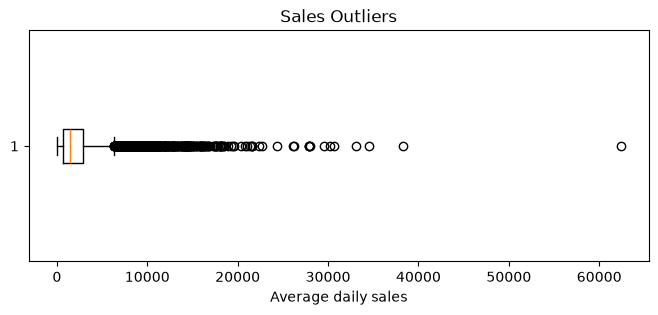

In [83]:
plt.figure(figsize=(8,3))
plt.boxplot(target, vert=False, showfliers=True)

plt.xlabel("Average daily sales")
plt.title("Sales Outliers")

plt.show()

The mean ($2349.19) is a lot greater than the median ($1484), which tells us the data is right-skewed. A small number of high-sales retailers are bringing the average up.

The values are very spread out since std > mean
max is a lot greater than our median (unusually high sales retailers)

We will perform a logarithmic transformation of the target variable to improve predictive accuracy

### Log Transformation Target: avg_daily_sales

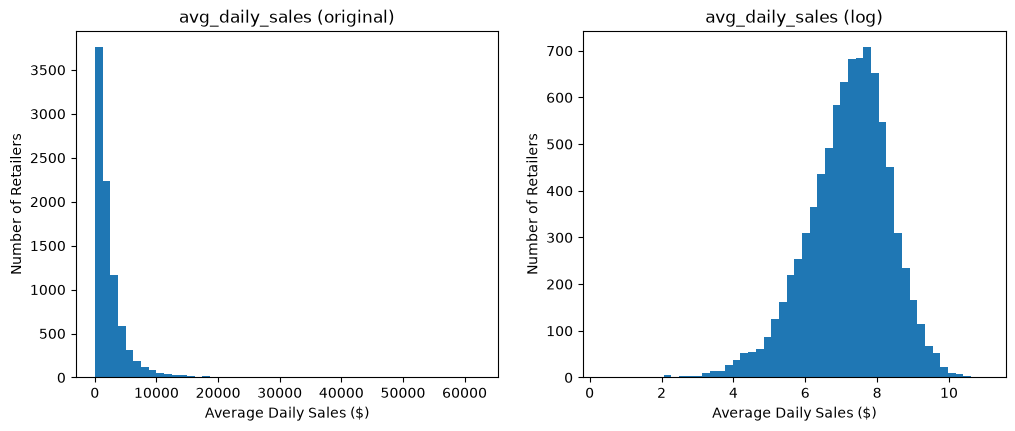

original skew value: 4.4
after log skew value: -0.64


In [82]:
# Taget variable overview
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# Original sales distribution 
ax[0].hist(target, bins=50)
ax[0].set_title("avg_daily_sales (original)")
ax[0].set_xlabel("Average Daily Sales ($)")
ax[0].set_ylabel("Number of Retailers")

# Sales distribution after log transform
ax[1].hist(np.log1p(target), bins=50)
ax[1].set_title("avg_daily_sales (log)")
ax[1].set_xlabel("Average Daily Sales ($)")
ax[1].set_ylabel("Number of Retailers")

plt.show()

print("original skew value:", round(target.skew(), 2))
print("after log skew value:", round(np.log1p(target).skew(), 2))

## Business Type, Chain & NYC

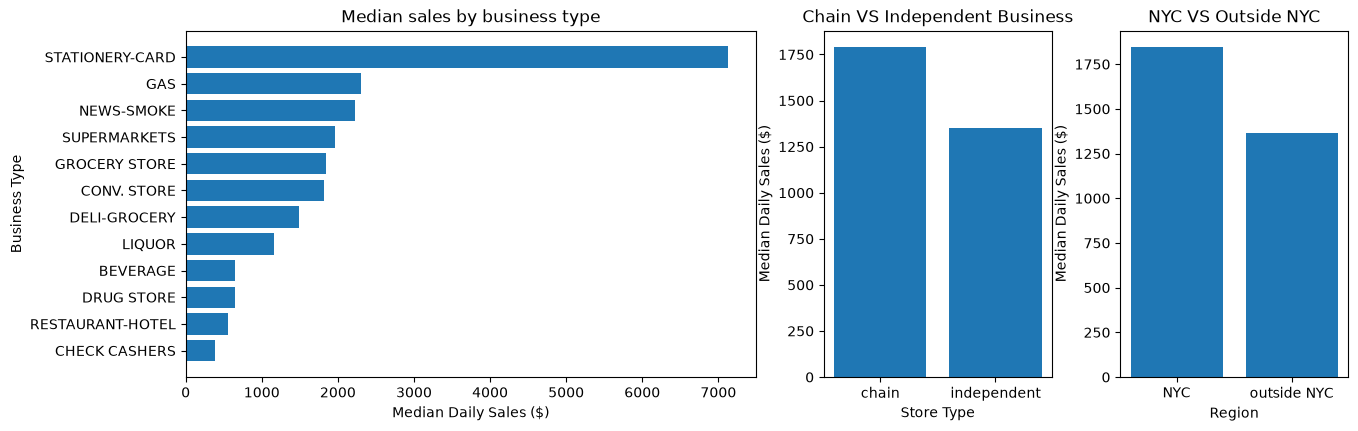

bg_geoid
NYC            1845.81
outside NYC    1367.75
Name: avg_daily_sales, dtype: float64
chain
chain          1790.37
independent    1352.61
Name: avg_daily_sales, dtype: float64


In [150]:
fig, ax = plt.subplots(1, 3, figsize=(15,4.5), gridspec_kw={"width_ratios": [2.5, 1, 1]})

counts = df["bustype"].value_counts()
#business type has at least 100 stores
store_count = counts[counts >= 100].index

bustype_median = df[df['bustype'].isin(store_count)].groupby("bustype")["avg_daily_sales"].median().sort_values()

# Median Sales by Business Type
ax[0].barh(bustype_median.index, bustype_median.values)
ax[0].set_title("Median sales by business type")
ax[0].set_xlabel("Median Daily Sales ($)")
ax[0].set_ylabel("Business Type")

# Chain 
chain_median = df.groupby("chain")["avg_daily_sales"].median()
ax[1].bar(chain_median.index, chain_median.values)
ax[1].set_title("Chain VS Independent Business")
ax[1].set_xlabel("Store Type")
ax[1].set_ylabel("Median Daily Sales ($)")

# In NYC or outside NYC 

nyc = df["bg_geoid"].astype("int64").astype(str).str[2:5].isin(["005", "047", "061", "081", "085"])
region = nyc.map({True: "NYC", False: "outside NYC"})
region_median = df.groupby(region)["avg_daily_sales"].median()
ax[2].bar(region_median.index, region_median.values)
ax[2].set_title("NYC VS Outside NYC")
ax[2].set_xlabel("Region")
ax[2].set_ylabel("Median Daily Sales ($)")


plt.show()
print(region_median.round(2))
print(chain_median.round(2))

## Features's with Sales Correlation & Relationship

Focus on Nearby Business & competition, Walkability & Traffic, Population, Income, Poverty, Employment, 

                               pearson_w_sales  spearman_w_sales  \
feature                                                            
commercial_places_within_1_mi            0.077             0.134   
competitors_within_1_mi                  0.102             0.130   
aadt_count                               0.032             0.101   
NatWalkInd                               0.128             0.101   
rac_c000                                 0.068             0.075   
median_household_income                  0.040             0.059   
total_population                         0.060             0.048   
family_households_proportion             0.012             0.028   
wac_c000                                 0.004             0.020   
unemployment_rate                        0.025             0.018   
poverty_rate                             0.001            -0.027   
rac_ce01_prop                           -0.048            -0.091   

                               person_log_w_sal

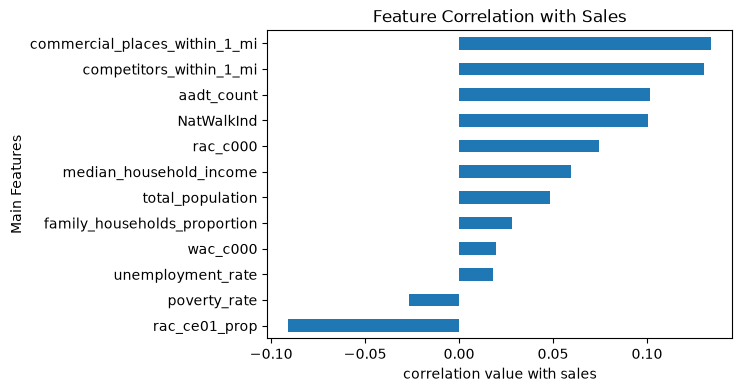

In [ ]:

original_df = pd.read_parquet('../data/modeling/train_data.parquet').copy()
log_avg_sales = np.log1p(df['avg_daily_sales'])
rows = []

main_features = ['competitors_within_1_mi',
       'aadt_count','median_household_income', 'total_population', 'poverty_rate','unemployment_rate', 
       'family_households_proportion', 'NatWalkInd', 'commercial_places_within_1_mi', 'rac_c000', 'rac_ce01_prop', 'wac_c000'
       ]

for features in main_features:
    x = pd.to_numeric(original_df[features], errors='coerce')
    rows.append({
        'feature': features,
        'pearson_w_sales': x.corr(target, method='pearson'),
        'spearman_w_sales': x.corr(target, method='spearman'),
        'person_log_w_sales': x.corr(np.log1p(target))
    }
    )
correlation_table = pd.DataFrame(rows).set_index('feature')
print(correlation_table.round(3).sort_values('spearman_w_sales', ascending=False))

corr_spearman = df[main_features].corrwith(log_avg_sales, method="spearman").sort_values()
corr_spearman.plot.barh(figsize=(6,4),)

plt.title("Feature Correlation with Sales")
plt.ylabel("Main Features")
plt.xlabel("correlation value with sales")
plt.show()



ScatterPlot: Features VS Sales

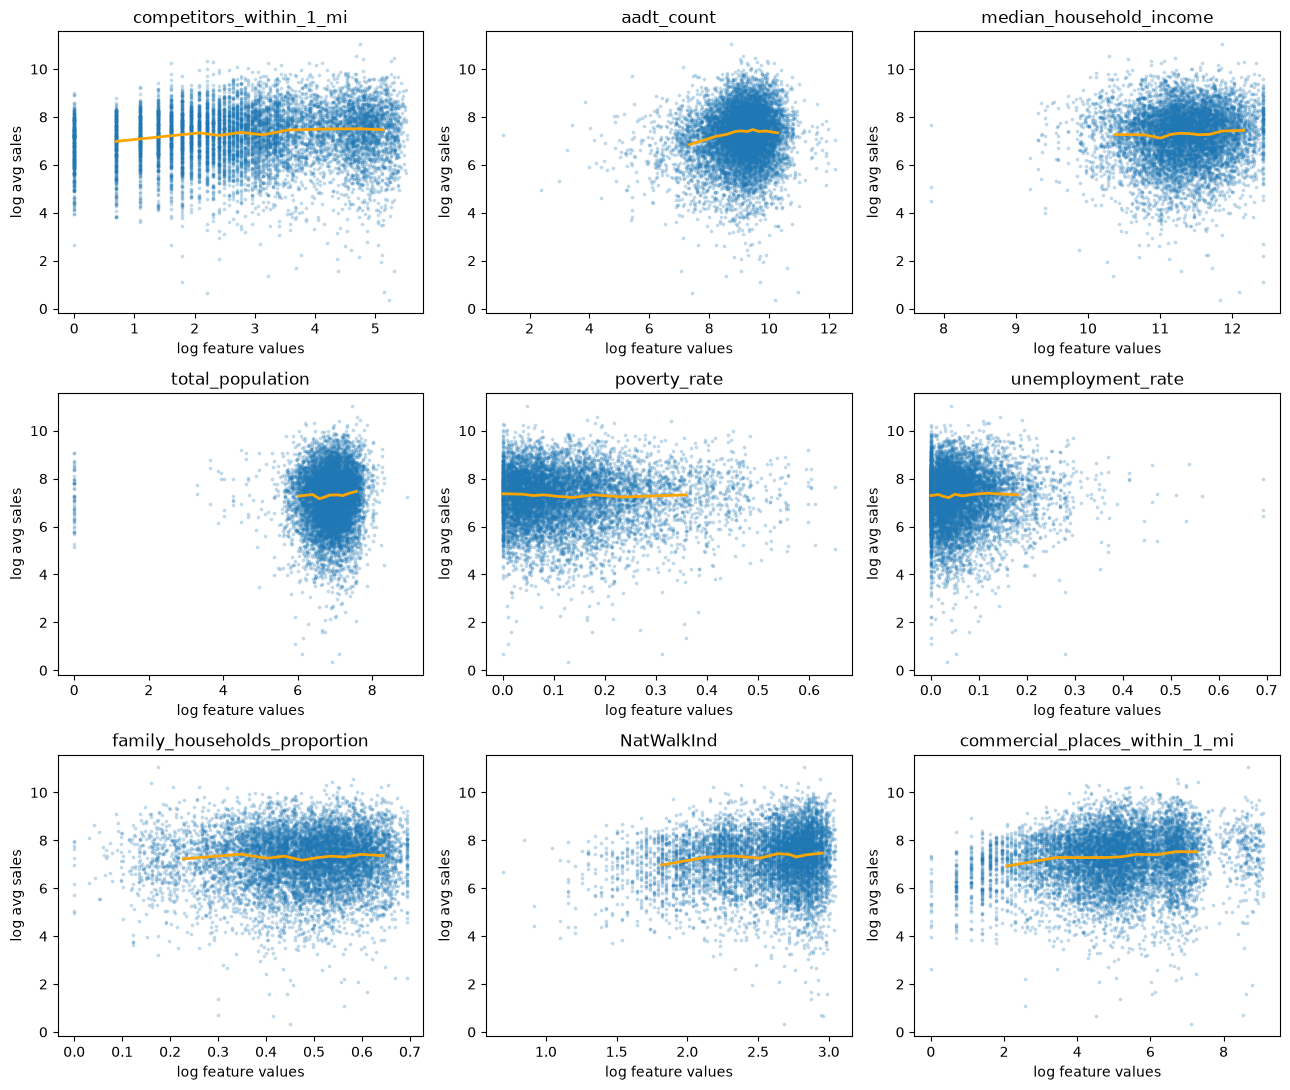

In [121]:
fig, axes = plt.subplots(3, 3, figsize=(13,11))

for ax, col in zip(axes.flat, main_features):
    data = pd.DataFrame({
        "x": np.log1p(df[col]),
        #"x": (df[col]),
        "y": log_avg_sales
    }).dropna()

    ax.scatter(x=data["x"], y=data["y"], s=3, alpha=0.2)

    #plot medain as a trend line
    trend = data.groupby(pd.qcut(data["x"], 10, duplicates="drop"), observed=True).median()
    ax.plot(trend["x"], trend["y"], color="orange", linewidth=2)
    ax.set_title(col)
    ax.set_ylabel("log avg sales")
    ax.set_xlabel("log feature values")


plt.tight_layout()
plt.show()

Insight: 

group = {
    "Traffic": ['aadt_count', 'aadt_lanes', 'dist_to_read_m'],
    "Nearby Places" :['commercial_places_within_1_mi','community_places_within_1_mi','competitors_within_1_mi'],
    "Walkability/Density": ['D1B', 'D1C', 'D3A', 'NatWalkInd'],
    "Jobs at the location": [c for c in features if c.startswith("wac_") ]
}
<!-- numeric_features = ['', ,
       'median_household_income', 'total_population', 'age_18_29_proportion', 'age_30_64_proportion',
       'poverty_rate', 'bachelors_degree_proportion_25plus', 'post_grad_degree_proportion_25plus',
       'labor_force_participation_rate', 'unemployment_rate', 'owner_occupied_proportion',
       'family_households_proportion', 'no_vehicle_households_proportion',
       

                              features  avg corr  \
groups                                             
Nearby Places                        3  0.129130   
Walkability/Density                  4  0.126435   
Jobs where people live (RAC)         3  0.055283   
Traffic                              3  0.050177   
Demographics                        12  0.041644   
Jobs at the location                23  0.031510   

                                             strongest feature  
groups                                                          
Nearby Places                    commercial_places_within_1_mi  
Walkability/Density                                        D1B  
Jobs where people live (RAC)                     rac_ce01_prop  
Traffic                                             aadt_count  
Demographics                  no_vehicle_households_proportion  
Jobs at the location                                 wac_cns01  


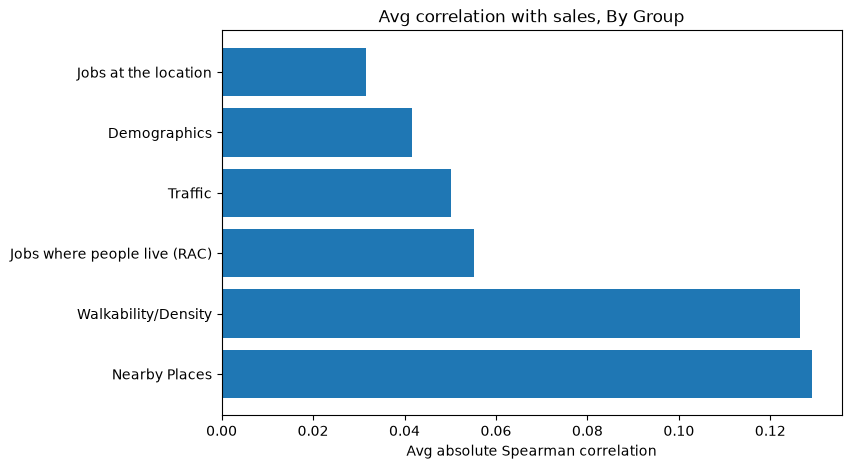

In [161]:
features = [data for data in df.select_dtypes("number").columns if data not in ["avg_daily_sales", "longitude", "latitude"]]


groups = {
    "Traffic": ['aadt_count', 'aadt_lanes', 'dist_to_read_m'],
    "Nearby Places" :['commercial_places_within_1_mi','community_places_within_1_mi','competitors_within_1_mi'],
    "Walkability/Density": ['D1B', 'D1C', 'D3A', 'NatWalkInd'],
    "Jobs at the location": [c for c in features if c.startswith("wac_")],
    "Jobs where people live (RAC)":[c for c in features if c.startswith("rac_") ]
}

# the rest group it in demographics
groups["Demographics"] = [c for c in features if c not in sum(groups.values(), [])]

all_corr = df[features].corrwith(log_avg_sales, method="spearman")

summary = pd.DataFrame([
    { "groups": g, "features": len(cols),
    "avg corr": all_corr[cols].abs().mean(),
    "strongest feature": all_corr[cols].abs().idxmax()}
    for g, cols in groups.items()
]).set_index("groups").sort_values("avg corr", ascending=False)

print(summary)


fig, ax = plt.subplots(figsize=(8,5))

ax.barh(summary.index, summary["avg corr"])
ax.set_title("Avg correlation with sales, By Group")
ax.set_xlabel("Avg absolute Spearman correlation")

plt.show()


Binned Trends 

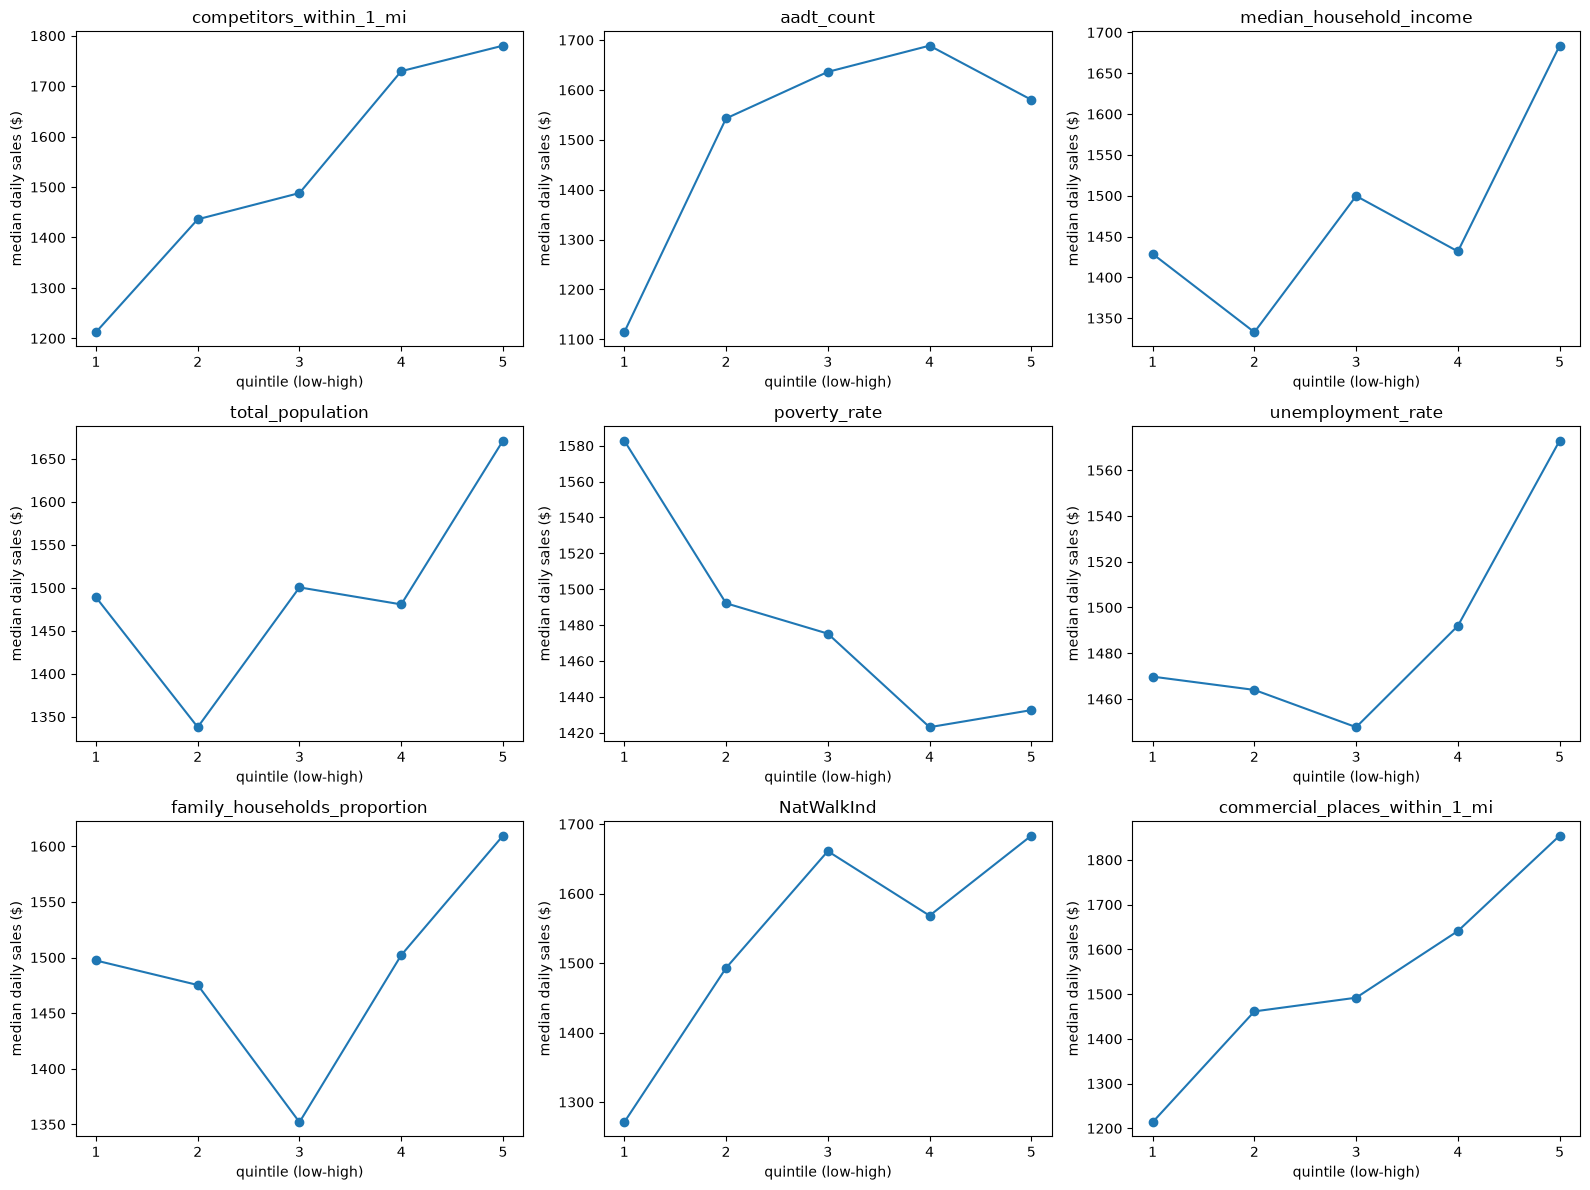

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(16,12))
TARGET = "avg_daily_sales"
for ax, feature in zip(axes.flat, main_features):
    data = df[[feature, TARGET]].apply(pd.to_numeric, errors="coerce").dropna()
    group = pd.qcut(data[feature].rank(method="first"), 5, labels=False) + 1
    data.groupby(group)[TARGET].median().plot(ax=ax, marker="o", title=feature)

    ax.set_xticks(range(1,6))
    ax.set_xlabel("quintile (low-high)")
    ax.set_ylabel("median daily sales ($)")


plt.tight_layout()
plt.show()

## Model

## Validation

## Test